In [116]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')
dataset = pd.read_csv('Placement.csv')

In [117]:
dataset

,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
210,211,M,80.60,Others,82.00,Others,Commerce,77.60,Comm&Mgmt,No,91.0,Mkt&Fin,74.49,Placed,400000.0
211,212,M,58.00,Others,60.00,Others,Science,72.00,Sci&Tech,No,74.0,Mkt&Fin,53.62,Placed,275000.0
212,213,M,67.00,Others,67.00,Others,Commerce,73.00,Comm&Mgmt,Yes,59.0,Mkt&Fin,69.72,Placed,295000.0
213,214,F,74.00,Others,66.00,Others,Commerce,58.00,Comm&Mgmt,No,70.0,Mkt&HR,60.23,Placed,204000.0


In [118]:
dataset.isnull().sum()

sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64

In [119]:
dataset[dataset['salary'].isnull()]['status'].value_counts()

status
Not Placed    67
Name: count, dtype: int64

In [120]:
# 1) Replace the NaN values with correct value. And justify why you have chosen the same?

#Ans: We replaced the missing values in the salary column with zero because all 67 missing salary records belonged to students who were not placed. 
# We should not use the mean or median salary because those students did not receive a salary.

In [121]:
dataset['salary'] = dataset['salary'].fillna(0)
dataset.isnull().sum()

sl_no             0
gender            0
ssc_p             0
ssc_b             0
hsc_p             0
hsc_b             0
hsc_s             0
degree_p          0
degree_t          0
workex            0
etest_p           0
specialisation    0
mba_p             0
status            0
salary            0
dtype: int64

In [122]:
# 2) How many of them are not placed?

#Ans: A total of 67 students were not placed out of 215 students in the dataset. The remaining 148 students successfully placed.

In [123]:
dataset['status'].value_counts()

status
Placed        148
Not Placed     67
Name: count, dtype: int64

In [124]:
# 3)Find the reason for non placement from the dataset?

#Ans : The dataset indicates that students who were not placed generally had lower academic percentages compared with placed students.
# Also, work experience appears to be associated with better placement outcomes. Among the students who were not placed, 57 had no work experience.
# Students with Mkt&HR specialization also had more non-placement records than students with Mkt&Fin specialization.

In [125]:
dataset.groupby('status')[['ssc_p','hsc_p','degree_p', 'etest_p', 'mba_p']].mean()

,ssc_p,hsc_p,degree_p,etest_p,mba_p
status,,,,,
Not Placed,57.544030,58.395522,61.134179,69.587910,61.612836
Placed,71.721486,69.926554,68.740541,73.238041,62.579392


In [126]:
pd.crosstab( dataset['status'],dataset['workex'])

workex,No,Yes
status,,
Not Placed,57,10
Placed,84,64


In [127]:
pd.crosstab(dataset['status'],dataset['specialisation'])

specialisation,Mkt&Fin,Mkt&HR
status,,
Not Placed,25,42
Placed,95,53


In [128]:
#4) What kind of relation between salary and mba_p?

# Ans: The correlation coefficient is approximately 0.175. It indicates a weak positive correlation between MBA percentage and salary.
# There is a weak positive correlation between MBA percentage and salary. This means that salary tends to increase slightly when MBA percentage increases.

In [129]:
placed_data = dataset[dataset['status'] == 'Placed']
correlation = placed_data['salary'].corr(placed_data['mba_p'])
print("Correlation:", correlation)

Correlation: 0.17501294069527473


In [130]:
# 5) Which specialization is getting minimum salary?

# Ans: The Mkt&HR specialization receives the minimum average salary of approximately ₹270,377.36, whereas Mkt&Fin receives approximately ₹298,852.63.
# Therefore, Mkt&HR has the lower average salary in this dataset.

In [131]:
placed_data.groupby('specialisation')['salary'].mean()

specialisation
Mkt&Fin    298852.631579
Mkt&HR     270377.358491
Name: salary, dtype: float64

In [132]:
placed_data.groupby('specialisation')['salary'].mean().idxmin()

'Mkt&HR'

In [133]:
# 6)How many of them getting above 500000 salary?

# Ans: Only 3 students received a salary above ₹5,00,000. 

In [134]:
above_500000 = placed_data[ placed_data['salary'] > 500000]
above_500000.shape[0]

3

In [135]:
above_500000[ ['sl_no', 'specialisation', 'salary']]

,sl_no,specialisation,salary
119,120,Mkt&Fin,940000.0
150,151,Mkt&Fin,690000.0
177,178,Mkt&Fin,650000.0


In [136]:
# 7)Test the Analysis of Variance between etest_p and mba_p at signifancelevel 5%.(Make decision using Hypothesis Testing)

# Ans : Hypothesis testing decision
# Our decision rule:
# - If p-value is less than 0.05, reject H0.
# - If p-value is greater than 0.05, fail to reject H0.
# Here: p < 0.05

#Null Hypothesis (H0):
# - There is no significant difference between the mean of etest_p and mba_p.

# Alternative Hypothesis (H1):
# - There is a significant difference between the mean of etest_p and mba_p.

# Therefore, we reject the null hypothesis (H0).

#There is a statistically significant difference between the mean values of employability test percentage and MBA percentage at a 5% significance level.

In [137]:
import scipy.stats as stats

f_stat, p_value = stats.f_oneway(dataset['etest_p'],dataset['mba_p'])

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 98.64487057324706
P-value: 4.672547689133573e-21


In [138]:
stats.ttest_rel( dataset['etest_p'],dataset['mba_p'])

TtestResult(statistic=np.float64(10.840680769176654), pvalue=np.float64(4.1449406968815296e-22), df=np.int64(214))

In [139]:
# 8)Test the similarity between the degree_t(Sci&Tech) and specialisation(Mkt&HR) with respect to salary at significance level of 5%.
# (Make decision using Hypothesis Testing)

#Ans:

#Null Hypothesis (H0):
#There is no significant difference in the average salary between Sci&Tech degree students and Mkt&HR specialization students.

#Alternative Hypothesis (H1):
# There is a significant difference in their average salaries.

# Significance level = 5%.

#Since: p = 0.007497 < 0.05
# We reject the null hypothesis.

# There is a statistically significant difference between the average salaries of Sci&Tech degree students and Mkt&HR specialization students.

In [140]:
sci_tech_salary = placed_data[placed_data['degree_t'] == 'Sci&Tech']['salary']

mkt_hr_salary = placed_data[ placed_data['specialisation'] == 'Mkt&HR']['salary']

f_stat, p_value = stats.f_oneway(sci_tech_salary,mkt_hr_salary)

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 7.4768950210499785
P-value: 0.00749689621876708


In [141]:
print("Sci&Tech Mean:", sci_tech_salary.mean())
print("Mkt&HR Mean:",mkt_hr_salary.mean())

Sci&Tech Mean: 314609.756097561
Mkt&HR Mean: 270377.358490566


In [142]:
#9) Convert the normal distribution to standard normal distribution for salary column.

# Ans:

# We converted the salary column into standard normal scores using the Z-score formula.
# After standardization, the mean becomes approximately zero and the standard deviation becomes one.
# A positive Z-score indicates a salary above the average, whereas a negative Z-score indicates a salary below the average.

In [143]:
mean_salary = placed_data['salary'].mean()
std_salary = placed_data['salary'].std()
placed_data['salary_zscore'] = ( placed_data['salary'] - mean_salary) / std_salary
placed_data[['salary', 'salary_zscore']].head()

,salary,salary_zscore
0,270000.0,-0.199614
1,200000.0,-0.948618
2,250000.0,-0.413615
4,425000.0,1.458895
7,252000.0,-0.392215


In [144]:
print("Mean:", placed_data['salary_zscore'].mean())
print("Standard Deviation:",placed_data['salary_zscore'].std())

Mean: 2.2804581046354566e-16
Standard Deviation: 1.0000000000000002


In [145]:
# 10)What is the probability Density Function of the salary range from 700000 to 900000?

#Ans: PDF stands for Probability Density Function. It describes how the values of a continuous variable are distributed.

#For a range, we use the cumulative distribution function (CDF).
# P(700000 < X < 900000)
# = CDF(900000)-CDF(700000)

# Based on the fitted normal distribution, the estimated probability of a salary falling between ₹7,00,000 and ₹9,00,000 is approximately 0.00053774%.
# The probability is very low because this salary range is far above the average salary.

In [146]:
from scipy.stats import norm

mean_salary = placed_data['salary'].mean()
std_salary = placed_data['salary'].std()

pdf_700000 = norm.pdf(700000, mean_salary, std_salary)
pdf_900000 = norm.pdf(900000, mean_salary, std_salary)

print("PDF at 700000:", pdf_700000)
print("PDF at 900000:", pdf_900000)

PDF at 700000: 2.652345869945573e-10
PDF at 900000: 2.1803344095448313e-15


In [147]:
probability = ( norm.cdf(900000, mean_salary, std_salary)-norm.cdf(700000, mean_salary, std_salary))
print("Probability:", probability)
print("Percentage:", probability * 100)

Probability: 5.377445759013888e-06
Percentage: 0.0005377445759013888


In [148]:
placed_data[placed_data['salary'].between(700000, 900000)].shape[0]

0

In [149]:
# 11) Test the similarity between the degree_t(Sci&Tech)with respect to etest_p and mba_p at significance level of 5%.
# (Make decision using Hypothesis Testing)

#Ans: 
#Null Hypothesis (H0):
#There is no significant difference between the mean etest_p and mba_p values for Sci&Tech students.

#Alternative Hypothesis (H1):
#There is a significant difference between the mean etest_p and mba_p values for Sci&Tech students.

# Significance level = 5%.

#Since:p < 0.05

# We reject the null hypothesis.

#There is a statistically significant difference between the mean employability test percentage and MBA percentage among Sci&Tech students.

In [150]:
sci_tech_data = dataset[dataset['degree_t'] == 'Sci&Tech']

f_stat, p_value = stats.f_oneway(sci_tech_data['etest_p'],sci_tech_data['mba_p'])

print("F-statistic:", f_stat)
print("P-value:", p_value)

F-statistic: 20.53902604077106
P-value: 1.4289217003775155e-05


In [151]:
stats.ttest_rel(sci_tech_data['etest_p'],sci_tech_data['mba_p'])

TtestResult(statistic=np.float64(5.0049844583693615), pvalue=np.float64(5.517920600505392e-06), df=np.int64(58))

In [152]:
#12) Which parameter is highly correlated with salary?

#Ans: 

#The etest_p parameter has the highest positive correlation with salary, with a correlation coefficient of approximately 0.178. 
# The etest_p parameter has the highest positive correlation with salary among the original numerical parameters.

In [153]:
correlation = placed_data.corr(numeric_only=True)
salary_correlation = correlation['salary'].drop( ['salary', 'salary_zscore'], errors='ignore')
salary_correlation = salary_correlation.sort_values(ascending=False)

In [154]:
print(salary_correlation)
print("Highest correlated parameter:",salary_correlation.idxmax())

etest_p     0.178307
mba_p       0.175013
hsc_p       0.076819
sl_no       0.063764
ssc_p       0.035330
degree_p   -0.019272
Name: salary, dtype: float64
Highest correlated parameter: etest_p


In [155]:
#13) plot any useful graph and explain it

#The box plot helps us compare the salary distribution between Mkt&Fin and Mkt&HR specializations.
#From the dataset, Mkt&Fin has a higher average salary than Mkt&HR.
# The graph also helps identify salary variation and potential outliers in both specializations.

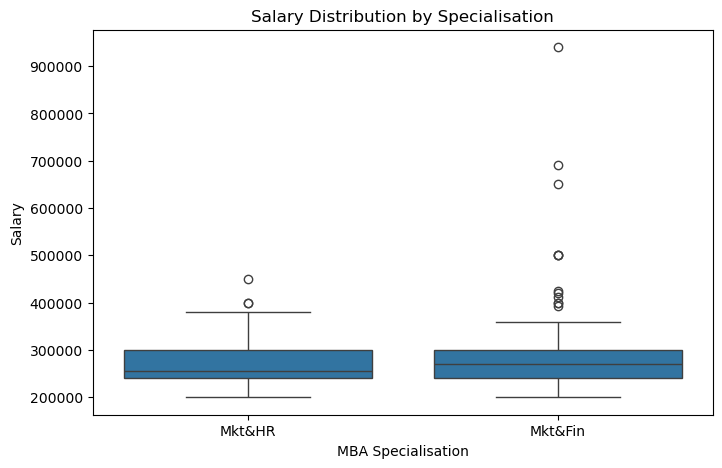

In [156]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(data=placed_data, x='specialisation',y='salary')

plt.title('Salary Distribution by Specialisation')
plt.xlabel('MBA Specialisation')
plt.ylabel('Salary')

plt.show()